#### AutoMPG
- 398 개의 instance
- 7 개의 feature
    - 연비를 target으로 설정
    - 입력 feature는 weight만 사용하여 선형회귀 모델 생성

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import *
from sklearn.preprocessing import MinMaxScaler

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

#### Define make_DataSet, train, evaluate, learning_curve

In [4]:
def make_DataSet(x_train, x_val, y_train, y_val, batch_size= 32):
    x_train_tensor = torch.tensor(x_train, dtype= torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype= torch.float32).view(-1,1)
    x_val_tensor = torch.tensor(x_val, dtype= torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype= torch.float32).view(-1,1)

    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)

    train_loader = DataLoader(train_dataset, batch_size= batch_size, shuffle=True)

    return train_loader, x_val_tensor, y_val_tensor

In [ ]:
def train(dataloader, model, loss_fn, optimizer, device):
    size = len(dataloader.dataset)  # dataloader가 사용하는 데이터셋의 샘플 수
    num_batches = len(dataloader)   # 318개의 인스턴스를 배치당 최대 32개씩 나눈값 = 10 개
    tr_loss = 0
    
    model.train()
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        pred = model(x)
        loss = loss_fn(pred, y)
        tr_loss += loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    tr_loss /= num_batches

    return tr_loss.item()

In [ ]:
def evaluate(x_val_tensor, y_val_tensor, model, loss_fn, device):   # optimizer 필요 X
    model.eval()
    with torch.no_grad():
        x, y = x_val_tensor.to(device), y_val_tensor.to(device)
        pred = model(x)
        val_loss = loss_fn(pred, y).item()

    return val_loss, pred

In [7]:
def learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label= 'train error', marker= '.')
    plt.plot(epochs, val_loss_list, label= 'val error', marker= '.')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()

#### Input Dataset

In [8]:
data = sns.load_dataset('mpg')

print(data.head())
print(data.shape)
print(data.isnull().sum())  # 무게에는 결측치 존재하지 않음

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
(398, 9)
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


In [9]:
# 자동차 무게와 연비만 선택
target = 'mpg'
feature = 'weight'
x = data.loc[:, [feature]]
# 단일변수회귀모델의 단순 x 데이터는 series로 출력 되기 때문에 
# 대괄호를 하나 더 붙인 [:, [feature]]으로 데이터프레임으로 변환
y = data.loc[:, target]

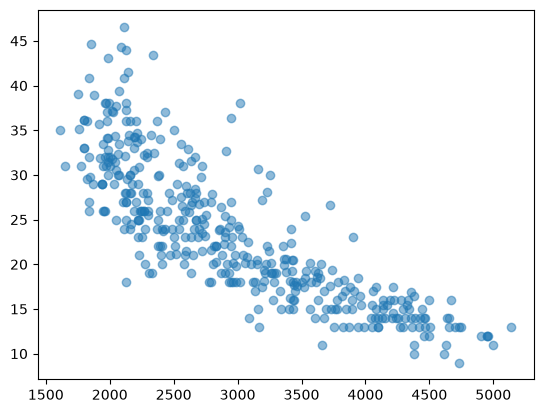

In [10]:
# 그래프 보기
plt.scatter(x, y, alpha=0.5)

In [11]:
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size= .2, random_state= 42)

scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)  
x_val = scaler.transform(x_val)

y_train = y_train.values
y_val = y_val.values

train_loader, x_val_tensor, y_val_tensor = make_DataSet(x_train, x_val, y_train, y_val, batch_size= 32)

In [12]:
# 모델 선언
# LR, EPOCH 등의 하이퍼파라미터 변경 시, model 선언 cell만 초기화할 수 있도록 같은 cell에 배치
LR = 1e-2
EPOCH = 50

n_feature = x.shape[1]
model = nn.Sequential(nn.Linear(n_feature, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
    ).to(device)
loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr= LR)

In [13]:
# 학습 / 검증
tr_loss_list, val_loss_list = [], []

for ep in range(EPOCH):
    tr_loss = train(train_loader, model, loss_fn, optimizer, device)
    val_loss, _ = evaluate(x_val_tensor, y_val_tensor, model, loss_fn, device)
    
    tr_loss_list.append(tr_loss)
    val_loss_list.append(val_loss)
    
    print(f'Epoch {ep+1}, train loss {tr_loss:.4f}, eval loss {val_loss:.4f}')

Epoch 1, train loss 608.4634, eval loss 565.9052
Epoch 2, train loss 583.7797, eval loss 538.7392
Epoch 3, train loss 552.6517, eval loss 502.2776
Epoch 4, train loss 509.9492, eval loss 453.8290
Epoch 5, train loss 454.7017, eval loss 393.8818
Epoch 6, train loss 389.4365, eval loss 326.9778
Epoch 7, train loss 319.7066, eval loss 259.1605
Epoch 8, train loss 252.1337, eval loss 198.6231
Epoch 9, train loss 195.3463, eval loss 152.1334
Epoch 10, train loss 153.4013, eval loss 123.1555
Epoch 11, train loss 129.0951, eval loss 108.4093
Epoch 12, train loss 116.4064, eval loss 101.6593
Epoch 13, train loss 110.0691, eval loss 97.2815
Epoch 14, train loss 105.4932, eval loss 93.0356
Epoch 15, train loss 100.7561, eval loss 88.6228
Epoch 16, train loss 96.3964, eval loss 83.9800
Epoch 17, train loss 91.9140, eval loss 79.7065
Epoch 18, train loss 87.5759, eval loss 75.3471
Epoch 19, train loss 83.2997, eval loss 71.3276
Epoch 20, train loss 79.4575, eval loss 67.3343
Epoch 21, train loss 7

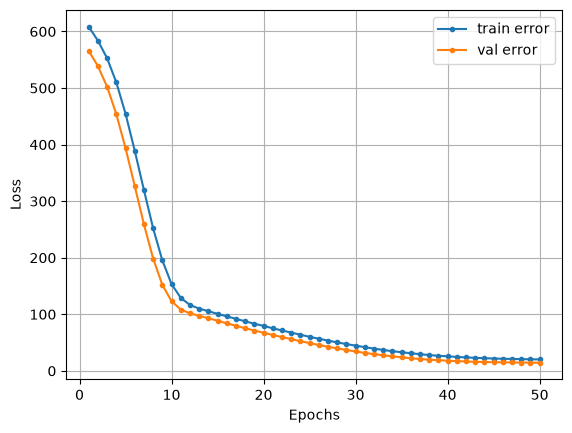

In [14]:
learning_curve(tr_loss_list, val_loss_list)

In [20]:
# 예측 결과
_, pred = evaluate(x_val_tensor, y_val_tensor, model, loss_fn, optimizer, device)

# CUDA 텐서라면 NumPy로 바로 변환할 수 없음에 유의하여 CPU로 옮겨주기
y_true = y_val_tensor.cpu().numpy()
y_pred = pred.cpu().numpy()
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(val_loss)

print(f'MSE: {val_loss:.4f}') # MSELoss
print(f'MAE: {mae:.4f}')      # MAELoss
print(f'RMSE: {rmse:.4f}')    # RSMELoss | MSE에 제곱근을 씌워 기존 데이터와 동일한 단위로 해석

MSE: 14.4063
MAE: 2.9582
RMSE: 3.7956


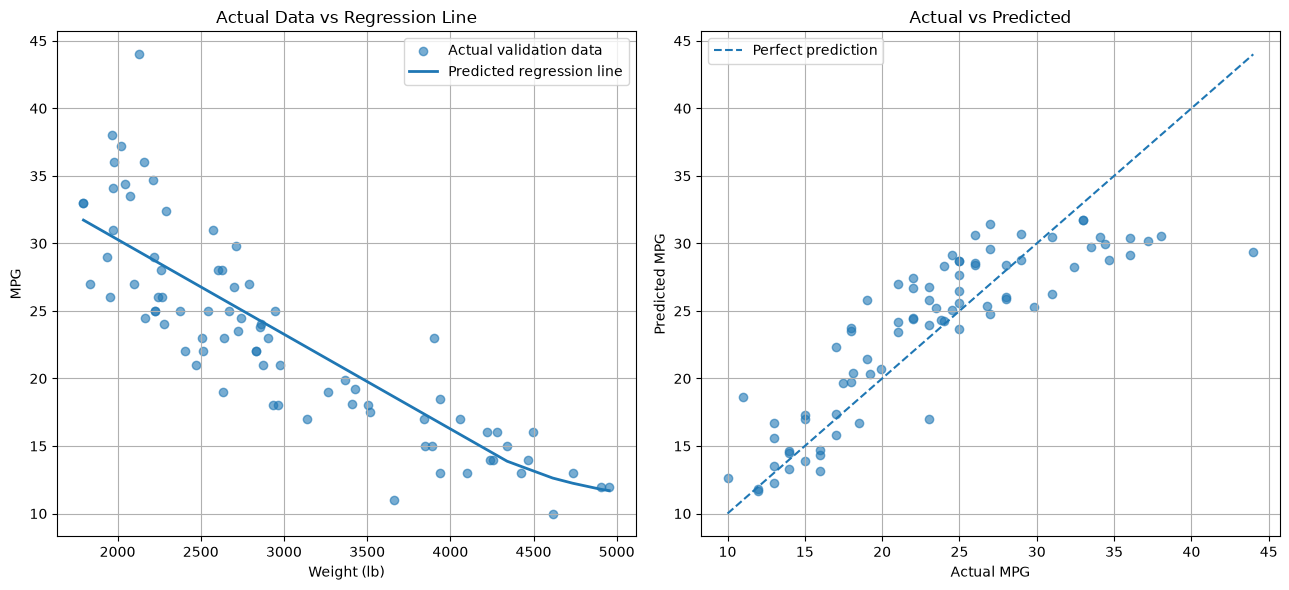

In [25]:
# 검증 데이터 예측
model.eval()
with torch.no_grad():
    pred = model(x_val_tensor.to(device))

# 그래프에 사용할 NumPy 배열로 변환
x_val_original = scaler.inverse_transform(
    x_val_tensor.cpu().numpy()
).ravel()

y_actual = y_val_tensor.cpu().numpy().ravel()
y_pred = pred.cpu().numpy().ravel()

# 원래 무게 기준으로 정렬
# 예측값도 동일한 인덱스로 정렬하여 대응 관계 유지
# argsort() : 정렬된 순서에 해당하는 인덱스 반환하는 함수
sort_idx = np.argsort(x_val_original)
x_sorted = x_val_original[sort_idx]
y_pred_sorted = y_pred[sort_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# 1. 실제 검증 데이터와 예측 회귀선
axes[0].scatter(
    x_val_original,
    y_actual,
    alpha=0.6,
    label='Actual validation data'
)
axes[0].plot(
    x_sorted,
    y_pred_sorted,
    linewidth=2,
    label='Predicted regression line'
)
axes[0].set_xlabel('Weight (lb)')
axes[0].set_ylabel('MPG')
axes[0].set_title('Actual Data vs Regression Line')
axes[0].legend()
axes[0].grid(True)

# 2. 실제 연비와 예측 연비 비교
axes[1].scatter(y_actual, y_pred, alpha=0.6)

min_val = min(y_actual.min(), y_pred.min())
max_val = max(y_actual.max(), y_pred.max())

axes[1].plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle='--',
    label='Perfect prediction'
)
axes[1].set_xlabel('Actual MPG')
axes[1].set_ylabel('Predicted MPG')
axes[1].set_title('Actual vs Predicted')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()